<a href="https://colab.research.google.com/github/ArielaLevkov/ImageProcessing_TA_2026/blob/main/recitations/04_Recitation_Convolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# תרגול 4 - קונבולוציה:


In [5]:
import os
import requests
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
import PIL

In [6]:
GITHUB_PATH = 'https://raw.githubusercontent.com/ArielaLevkov/ImageProcessing_TA/main/images/'

def read_file(fname:str, file_path:str=GITHUB_PATH) -> np.ndarray:
    '''
    Accept an image file name (defaulty located in GitHub) and return the image
    in a numpy array.

    Args:
        fname: the file name
        file_path: the file path.. Default value is Ariela's Github repo.

    Returns:
        the image converted into a Numpy array.
    '''
    file_path = os.path.join(file_path, fname)
    response = requests.get(file_path)
    fp = BytesIO(response.content)

    img_pil = PIL.Image.open(fp)
    return np.array(img_pil, dtype='int16')

In [7]:
def plot_images(img1:np.array, img2:np.array):
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))
    axes[0].imshow(img1,  cmap='gray')
    axes[1].imshow(img2,  cmap='gray')

<div dir="rtl">

# הצגת תמונות בצורה דינאמית:
בקונבולוציה כל שינוי מתרחש ברמת הפיקסל, ולכן כדי לראות מקרוב את ההשפעה של המסננים על אזורים שונים בתמונה. שימוש בPlotly מאפשר לבצע זום, להזיז את התצוגה, ולבחון ערכים ספציפיים של פיקסלים בצורה נוחה.
<div>


In [8]:
import plotly.express as px

img = read_file(fname='house.tiff') / 255
fig = px.imshow(img, color_continuous_scale='gray')
fig.update_layout(coloraxis_showscale=False)

<div dir="rtl">

# 4. קונבולוציה:
###מה זה קונבולוציה?

קונבולוציה היא פעולה מתמטית שבה מחשבים ערך חדש לכל פיקסל בתמונה בהתאם לערכי הפיקסלים בסביבתו, באמצעות מסנן (Kernel).

###למה צריך קונבולוציה?

קונבולוציה מאפשרת לבצע פעולות שונות על תמונה, כמו טשטוש, החלקה, הפחתת רעשים וגילוי קצוות, בהתאם למסנן שנבחר.

###איך היא עובדת בפועל?

מעבירים מסנן על פני התמונה. בכל מיקום מכפילים את ערכי הפיקסלים בערכי המסנן המתאימים וסוכמים את המכפלות לקבלת ערך חדש. בקונבולוציה הופכים את המסנן לפני ההזזה.


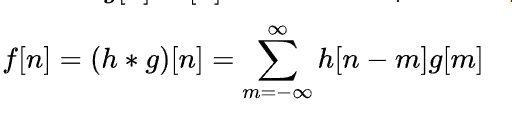

<div dir="rtl">

כאשר (h) הוא האות המקורי, (g) הוא המסנן, (n) הוא מיקום הפלט ו-(m) הוא אינדקס הסכימה. בכל מיקום מחושב סכום המכפלות לקבלת ערך הפלט.

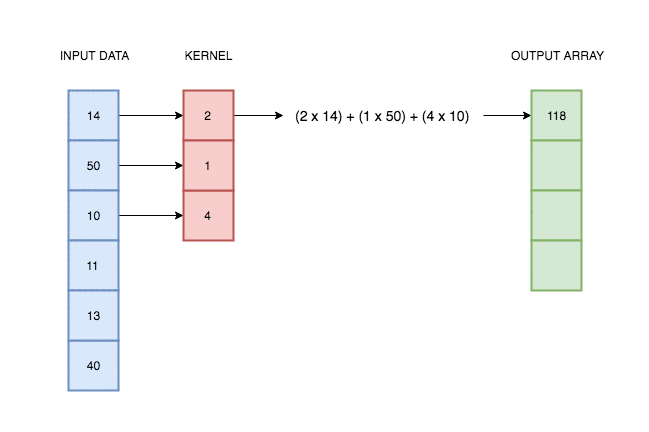

<div dir="rtl">

ספריית `scipy`:

In [9]:
from scipy.signal import convolve

<div dir="rtl">
שימושים:

* שימוש בconvolve לקונובלוציה חד ממדית
* שימוש בפרמטר `mode` הקובע איך לטפל בגבולות התמונה ע"י 3 מצבים: `valid`, `full` , `same`

# 4.1 Convolution - valid mode


<div dir="rtl">

מבצעים קונבולוציה רק במקומות שבהם המסנן מתאים כולו לתוך הדאטה ללא הוספת פיקסלים בשוליים.

In [10]:
convolve(in1=[14,50,10,11,13,40], in2=[4,1,2], mode='valid')

array([118, 154,  83, 195])

<div dir="rtl">

שימו לב שהמסנן (in2) מתהפך (כדי שיהיה קומוטטיבי):

In [11]:
convolve(in1=[4,1,2], in2=[14,50,10,11,13,40], mode='valid')

array([118, 154,  83, 195])

<div dir="rtl">

קונבולוציה ידנית בלי שימוש בפונקציה המובנית

In [12]:
in1 = np.array([14,50,10,11,13,40])
in2 = np.array([4,1,2])
print([np.dot(in1[i:i+len(in2)], np.flip(in2)) for i in range(0, len(in1)-len(in2)+1)])

[np.int64(118), np.int64(154), np.int64(83), np.int64(195)]


<div dir="rtl">

בvalid המסנן חייב להתאים בדיוק לתוך הקלט ולכן התוצאה קטנה יותר

## 4.2 Full and Same modes

<div dir="rtl">

במצב SAME -  שמירה על גודל התמונה המקורית

<div dir="rtl">

* SciPy עושה zero-padding למסנן בצדדים (עד לגודל של התמונה המקורית)

* מבצעת קונבולוציה רגילה

* לוקחת בדיוק את מרכז התוצאה כך שהאורך נשאר זהה

In [13]:
convolve(in1=[14,50,10,11,13,40], in2=[4,1,2], mode='same')

array([214, 118, 154,  83, 195,  66])

<div dir="rtl">

במצב FULL - מתקבלת התוצאה הגדולה ביותר האפשרית

* SciPy עושה zero-padding למסנן בצדדים (עד לגודל המקסימלי של הקונבולוציה)

* מבצעת קונבולוציה רגילה

In [14]:
convolve(in1=[14,50,10,11,13,40], in2=[4,1,2], mode='full')

array([ 56, 214, 118, 154,  83, 195,  66,  80])

<div dir="rtl">

# 4.3 קרוס-קורולציה:

In [15]:
from scipy.signal import correlate

<div dir="rtl">

קרוס-קורולציה היא פעולה הדומה מאוד לקונבולוציה,
אבל בלי היפוך (flip) של המסנן

<div dir="rtl">

קונבולוציה היא פעולה קומוטטיבית:

In [16]:
print(convolve(in1=[1,2,3,4,5], in2=[6,7,8,9,10], mode='same'))
print(convolve(in1=[6,7,8,9,10], in2=[1,2,3,4,5], mode='same'))

[ 40  70 110 114 106]
[ 40  70 110 114 106]


<div dir="rtl">

בעוד שקרולוציה לא קומוטטיבית:

In [17]:
print(correlate(in1=[1,2,3,4,5], in2=[6,7,8,9,10], mode='same'))
print(correlate( in1=[6,7,8,9,10], in2=[1,2,3,4,5], mode='same'))

[ 56  90 130 110  86]
[ 86 110 130  90  56]


<div dir="rtl">

שימו לב:

* ברוב המימושים המעשיים כולל CNN (רשתות קונבולוציה),
הפונקציה שמשתמשים בה היא קורלציה, ולא קונבולוציה אמיתית
* אופרטור הקונבולוציה:
$C=A \ast B$

<div dir="rtl">

# 4.4 מסנן ממוצע (Mean filter):

Low-pass filter מסנן רעש ותדרים גבוהים

<div dir="rtl">

בכל נקודה אנחנו מחליפים את הערך בממוצע של השכנים.

<div dir="rtl">

קונבולציה על 1D:

In [18]:
v = convolve(in1=[0,0,0,0,1,1,1,1], in2=[1/3,1/3,1/3], mode='same')
print([f'{a:.2f},' for a in v])

['0.00,', '0.00,', '0.00,', '0.33,', '0.67,', '1.00,', '1.00,', '0.67,']


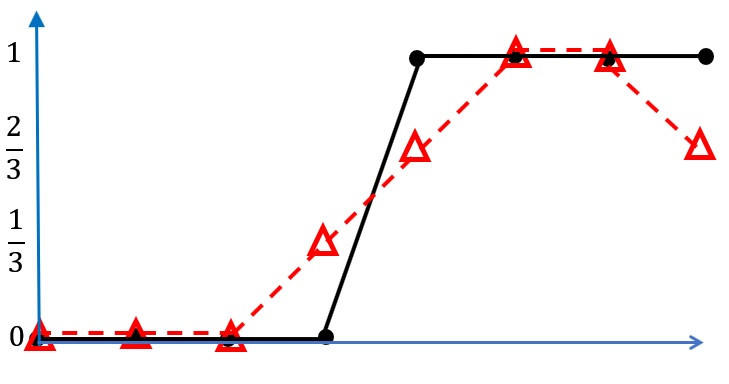

<div dir="rtl">

קונבולציה על 2D:

0.996078431372549


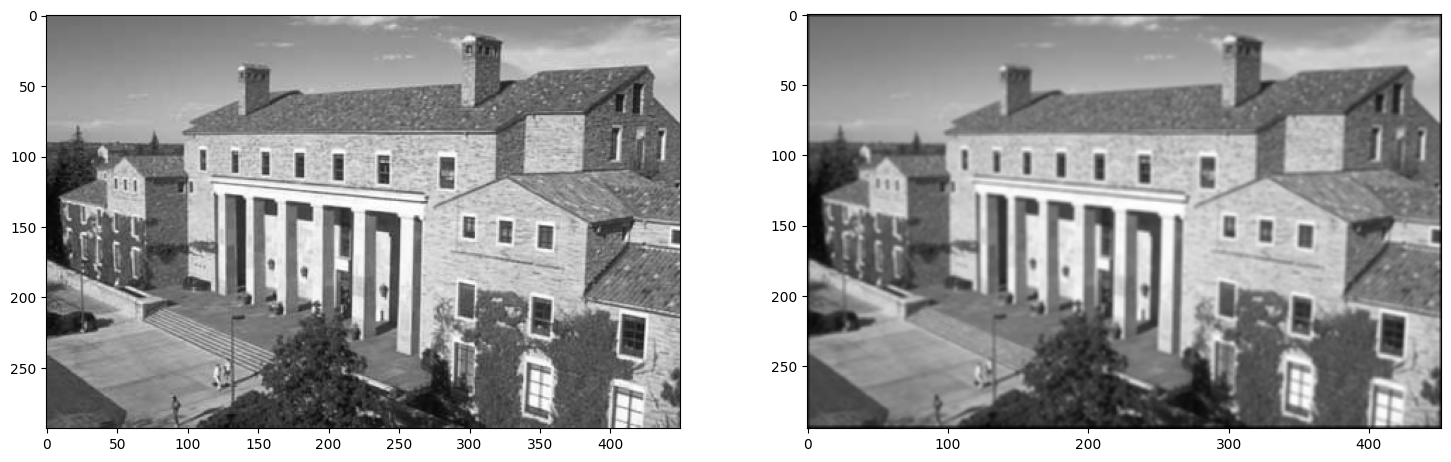

In [19]:
img = read_file(fname='house.tiff') / 255
print(img.max())
FILTER_SIZE = 3
filter=np.ones(shape=(FILTER_SIZE, FILTER_SIZE))
filter = filter / filter.sum()
img1 = convolve(in1=img, in2=filter)

plot_images(img, img1)

<div dir="rtl">

למה מחלקים בסכום של המסנן? (FILTER_SIZE = 9)

0.9800532558702492


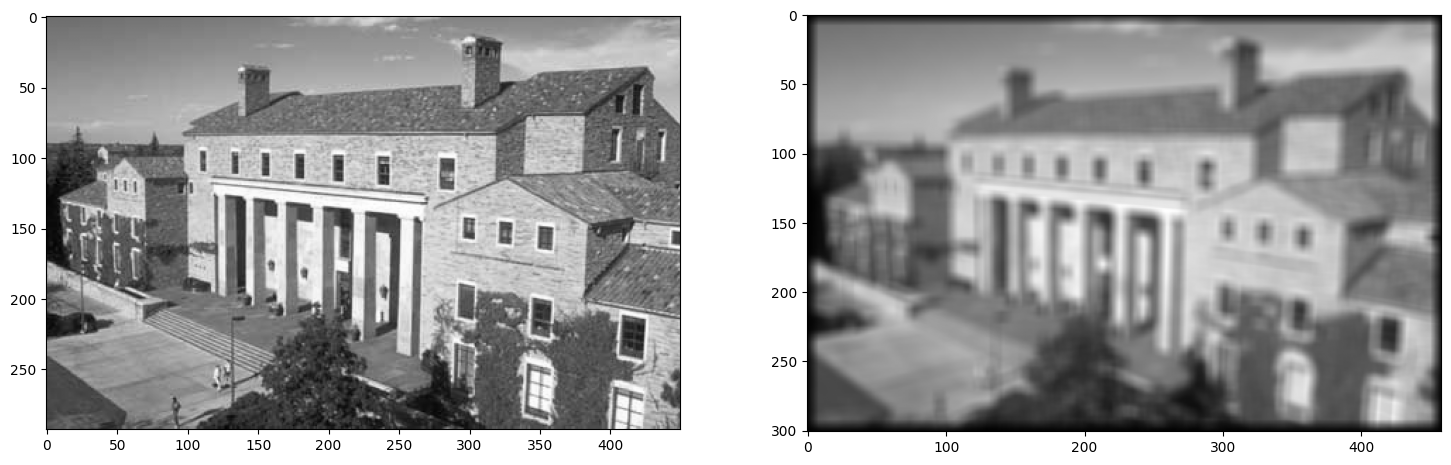

In [20]:
# here we devide:
FILTER_SIZE = 9
filter=np.ones(shape=(FILTER_SIZE, FILTER_SIZE))
filter = filter / filter.sum()

img1 = convolve(in1=img, in2=filter)

plot_images(img, img1)
print(img1.max())

79.38431372549022


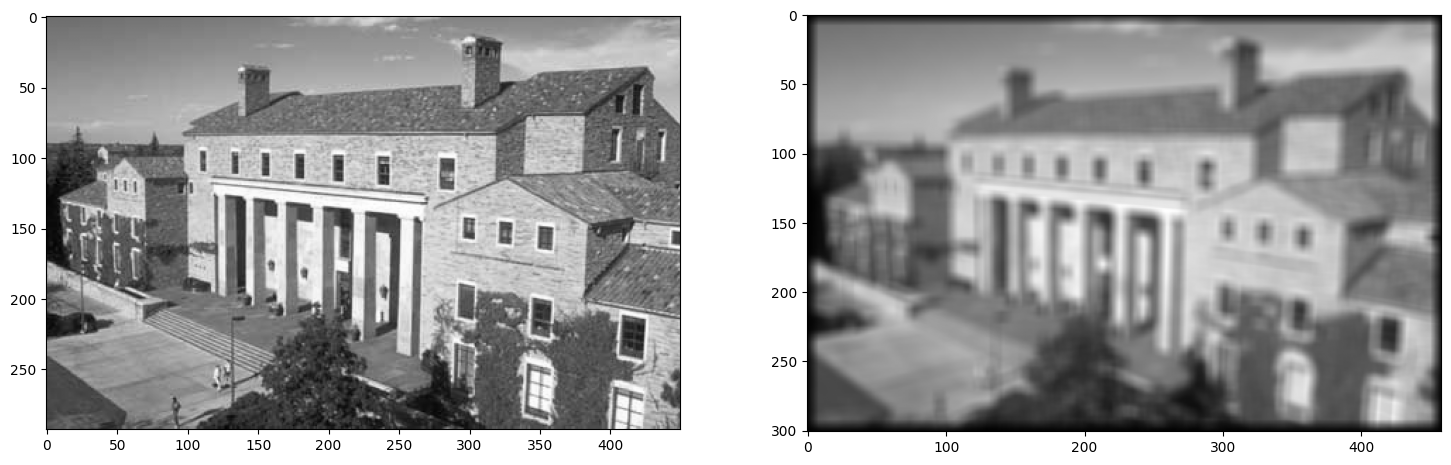

In [21]:
# here we don't devide:
FILTER_SIZE = 9
filter=np.ones(shape=(FILTER_SIZE, FILTER_SIZE))
filter = filter # / filter.sum()

img2 = convolve(in1=img, in2=filter)

plot_images(img, img2)
print(img2.max())

<div dir="rtl">

# 4.5 מסנן גאוסיאני:

Low-pass filter מסנן רעש ותדרים גבוהים אבל חכם יותר

בניגוד מסנן ממוצע שבו כל השכנים שווים,
במסנן גאוסיאני השכן המרכזי חשוב יותר, והשכנים הרחוקים תורמים פחות

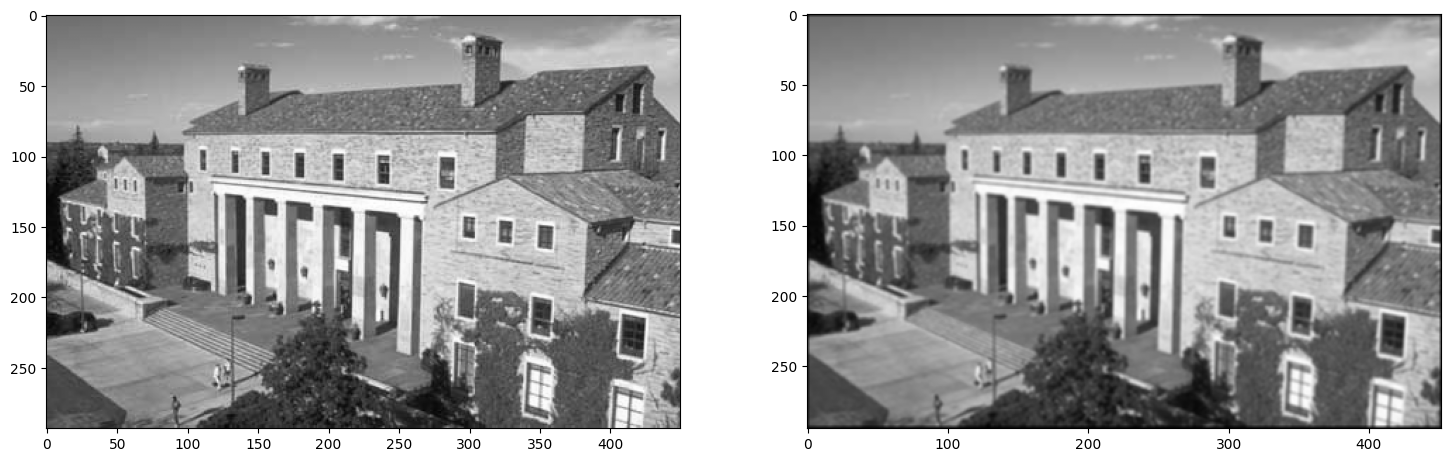

In [22]:
filter=np.array([[1,1,1],[1,2,1],[1,1,1]])
filter = filter / filter.sum()
img1 = convolve(in1=img, in2=filter)

plot_images(img, img1)

<div dir="rtl">


#4.5 Edge Detector גילוי קצוות

<div dir="rtl">

בעזרת קונבולוציה עם מסנן מתאים אפשר לגלות קצוות (שינויים חדים באות/בתמונה).

In [23]:
v = convolve(in1=[0,0,0,0,1,1,1,1], in2=[-1,2,-1], mode='same')
print([f'{a:.2f},' for a in v])

['0.00,', '0.00,', '0.00,', '-1.00,', '1.00,', '0.00,', '0.00,', '1.00,']


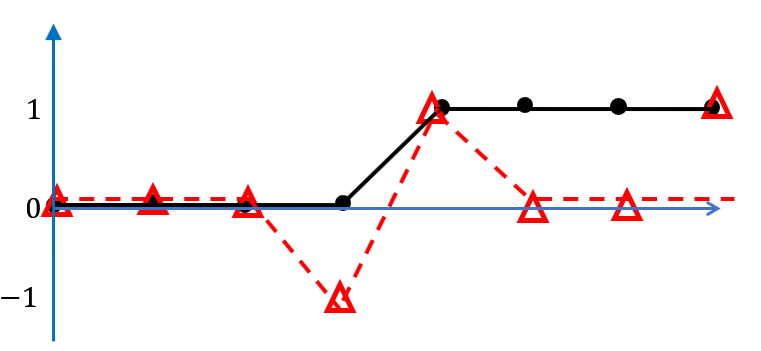

0.0
-0.7019607843137255


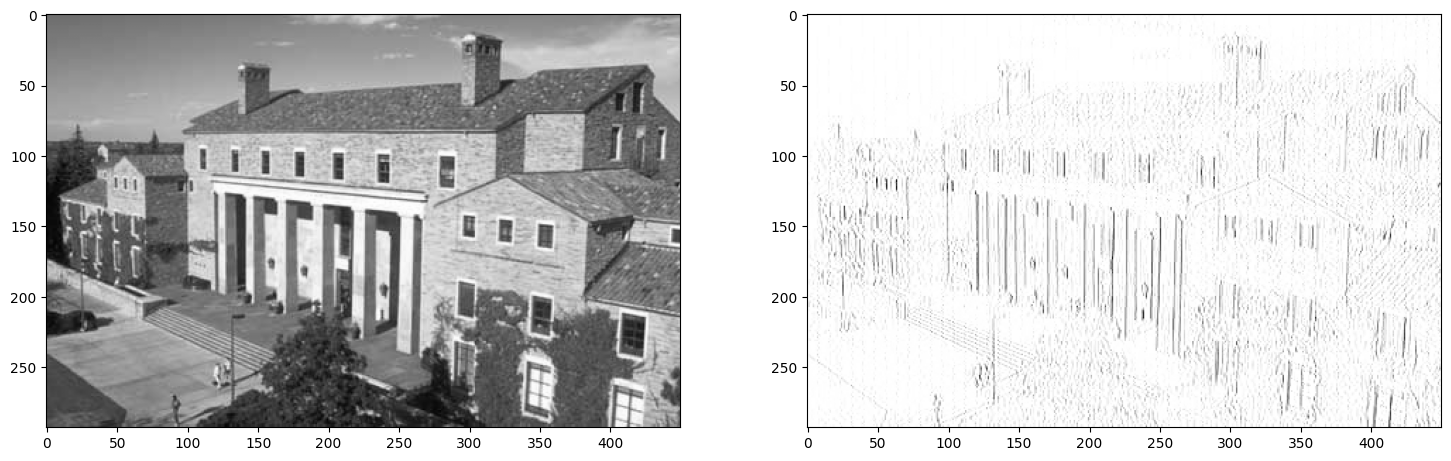

In [24]:
filter=np.array([[-1,2,-1]])
img1 = convolve(img, filter, 'same')
img1 = np.clip(img1, a_min=-1, a_max=0)
plot_images(img, img1)
print(img1.max())
print(img1.min())

<div dir="rtl">


המסנן הוא מסנן אופקי כי 1X3 ולכן הוא יגלה שינויים חדים בכיוון אופקי והוא מופיע בתמונה כקווים אנכיים. כל מקום שבו התמונה קופצת בבירור הופך לקצה

<div dir="rtl">

לקבלת הקצוות עם הערך השלילי נשתמש בערך מוחלט על התמונה:

1.3450980392156864
0.0


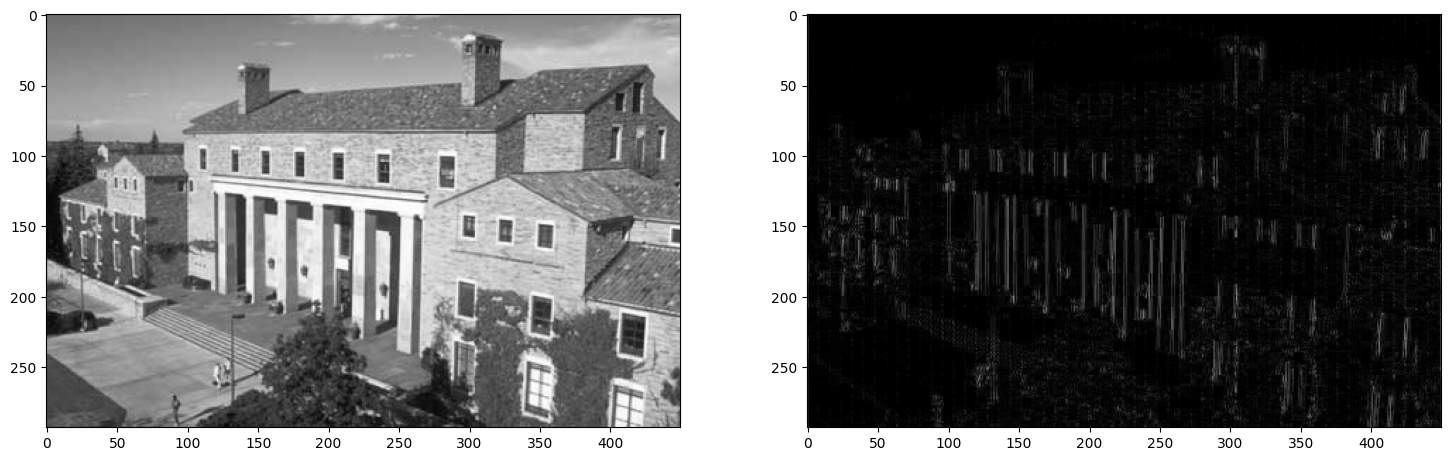

In [25]:
filter=np.array([[-1,2,-1]])
img1 = convolve(img, filter, 'same')
img1 = np.abs(img1)
plot_images(img, img1)
print(img1.max())
print(img1.min())